In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [3]:
excel_file=pd.ExcelFile(r"C:\Users\91945\Desktop\Analytics-3rd Sem Assignment\Python\For Prediction and Classification.xlsx")
print(excel_file.sheet_names)

['Dataset', 'Data Dictionary', 'Exercises']


In [4]:
df=pd.read_excel(r"C:\Users\91945\Desktop\Analytics-3rd Sem Assignment\Python\For Prediction and Classification.xlsx", sheet_name="Dataset")
df.head()

,Supplier,Order_Quantity_Units,Unit_Cost_INR,Lead_Time_Days,On_Time_Delivery_%,Defect_Rate_%,Freight_Cost_INR,Fill_Rate_%,Inventory_Cover_Days,Distance_km,Shipment_Frequency_per_Month,Total_Procurement_Cost_INR,Performance_Class
0,Supplier A,624,361.63,7.2,91.7,1.81,5850.15,98.1,9.3,1659,9,231507.27,High
1,Supplier B,913,518.35,9.0,77.2,1.30,11125.99,93.3,22.9,1048,18,484379.54,Low
2,Supplier A,792,519.73,5.7,88.7,2.31,7641.41,97.6,28.4,1510,17,419267.57,High
3,Supplier A,290,498.92,5.5,98.6,3.09,2814.69,97.9,32.9,1024,15,147501.49,High
4,Supplier A,613,494.56,7.5,88.2,1.21,10715.90,95.8,28.6,1280,12,313881.18,High


## Understand The Data

In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 200
Columns: 13


In [6]:
print(df.columns)

Index(['Supplier', 'Order_Quantity_Units', 'Unit_Cost_INR', 'Lead_Time_Days',
       'On_Time_Delivery_%', 'Defect_Rate_%', 'Freight_Cost_INR',
       'Fill_Rate_%', 'Inventory_Cover_Days', 'Distance_km',
       'Shipment_Frequency_per_Month', 'Total_Procurement_Cost_INR',
       'Performance_Class'],
      dtype='object')


## Data Type

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Supplier                      200 non-null    object 
 1   Order_Quantity_Units          200 non-null    int64  
 2   Unit_Cost_INR                 200 non-null    float64
 3   Lead_Time_Days                200 non-null    float64
 4   On_Time_Delivery_%            200 non-null    float64
 5   Defect_Rate_%                 200 non-null    float64
 6   Freight_Cost_INR              200 non-null    float64
 7   Fill_Rate_%                   200 non-null    float64
 8   Inventory_Cover_Days          200 non-null    float64
 9   Distance_km                   200 non-null    int64  
 10  Shipment_Frequency_per_Month  200 non-null    int64  
 11  Total_Procurement_Cost_INR    200 non-null    float64
 12  Performance_Class             200 non-null    object 
dtypes: fl

## Missing Value

In [8]:
df.isnull().sum()

Supplier                        0
Order_Quantity_Units            0
Unit_Cost_INR                   0
Lead_Time_Days                  0
On_Time_Delivery_%              0
Defect_Rate_%                   0
Freight_Cost_INR                0
Fill_Rate_%                     0
Inventory_Cover_Days            0
Distance_km                     0
Shipment_Frequency_per_Month    0
Total_Procurement_Cost_INR      0
Performance_Class               0
dtype: int64

In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


## Statistical Analysis

In [10]:
df.describe()

,Order_Quantity_Units,Unit_Cost_INR,Lead_Time_Days,On_Time_Delivery_%,Defect_Rate_%,Freight_Cost_INR,Fill_Rate_%,Inventory_Cover_Days,Distance_km,Shipment_Frequency_per_Month,Total_Procurement_Cost_INR
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.00000,200.000000,200.000000,200.000000
mean,529.875000,506.901100,7.471000,90.802500,3.046600,7389.573000,92.599500,21.91750,976.045000,11.760000,275729.396300
std,262.203073,64.031485,1.985287,6.253123,1.535313,3904.755333,4.538429,8.13773,499.975681,5.107134,142874.269329
min,51.000000,361.630000,2.600000,75.300000,0.200000,609.670000,81.600000,5.60000,62.000000,2.000000,28040.020000
25%,288.250000,456.715000,6.200000,86.825000,1.932500,4042.152500,89.375000,16.20000,555.250000,8.000000,155443.042500
50%,536.000000,503.885000,7.400000,91.400000,2.760000,7173.970000,93.300000,21.40000,968.000000,12.000000,273063.500000
75%,733.000000,550.465000,8.500000,95.525000,3.960000,10521.000000,96.225000,28.52500,1394.250000,16.000000,382421.652500
max,995.000000,645.030000,13.700000,100.000000,7.500000,17263.840000,100.000000,39.90000,1799.000000,20.000000,595569.280000


## Supplier Distribution

In [11]:
print(df["Supplier"].value_counts())

Supplier
Supplier A    100
Supplier B    100
Name: count, dtype: int64


## Check Performance Class

In [12]:
print(df["Performance_Class"].value_counts())

Performance_Class
High    100
Low     100
Name: count, dtype: int64


## PART A — REGRESSION / PREDICTION

In [13]:
a = [
    "Order_Quantity_Units",
    "Unit_Cost_INR",
    "Lead_Time_Days",
    "On_Time_Delivery_%",
    "Defect_Rate_%",
    "Freight_Cost_INR",
    "Fill_Rate_%",
    "Inventory_Cover_Days",
    "Distance_km",
    "Shipment_Frequency_per_Month"
]

In [14]:
X = df[a] # X = Independent/Input variables
y = df["Total_Procurement_Cost_INR"] # y = Dependent/Target variable

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [16]:
print("Train data:", X_train.shape)
print("Test data:", X_test.shape)

Train data: (160, 10)
Test data: (40, 10)


## Linear Regression

In [17]:
linear_model = LinearRegression()

In [18]:
linear_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [19]:
y_pred_linear = linear_model.predict(X_test)

## Linear Regression

In [20]:
# MAE (Mean Absolute Error)
mae_linear = mean_absolute_error(y_test, y_pred_linear)
print("Mean Absolute Error:", mae_linear)

Mean Absolute Error: 13999.371791532041


In [21]:
# RMSE (Root Mean Squared Error)
rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)
print("Root Mean Squared Error:", rmse_linear)

Root Mean Squared Error: 19554.239364842942


In [22]:
# R^2 Score
r2_linear = r2_score(y_test, y_pred_linear)
print("R2 Score:", r2_linear)

R2 Score: 0.9821095749470788


## R^2 = 0.9821, it means Variation = 98.2% in Procurement Cost

## Forest Regression

In [23]:
rf_regressor = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
rf_regressor.fit(X_train, y_train)
y_pred_rf = rf_regressor.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

MAE: 13667.685711250018
RMSE: 18328.50375534124
R2 Score: 0.984282161199087


## Compare Regression Model

In [45]:
regression_results = pd.DataFrame({
    "Model": ["Linear Regression","Random Forest Regression"],
    "MAE": [mae_linear, mae_rf],
    "RMSE": [rmse_linear, rmse_rf],
    "R2 Score": [r2_linear, r2_rf]
})
regression_results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,13999.371792,19554.239365,0.982110
1,Random Forest Regression,13667.685711,18328.503755,0.984282


## Important Features

In [46]:
feature_importance = pd.DataFrame({"Feature": a,"Importance": rf_regressor.feature_importances_})
feature_importance = feature_importance.sort_values(by="Importance", ascending=False)
print(feature_importance)

                        Feature  Importance
0          Order_Quantity_Units    0.910958
1                 Unit_Cost_INR    0.070854
5              Freight_Cost_INR    0.006107
8                   Distance_km    0.002450
7          Inventory_Cover_Days    0.001864
6                   Fill_Rate_%    0.001860
4                 Defect_Rate_%    0.001633
9  Shipment_Frequency_per_Month    0.001537
2                Lead_Time_Days    0.001406
3            On_Time_Delivery_%    0.001332


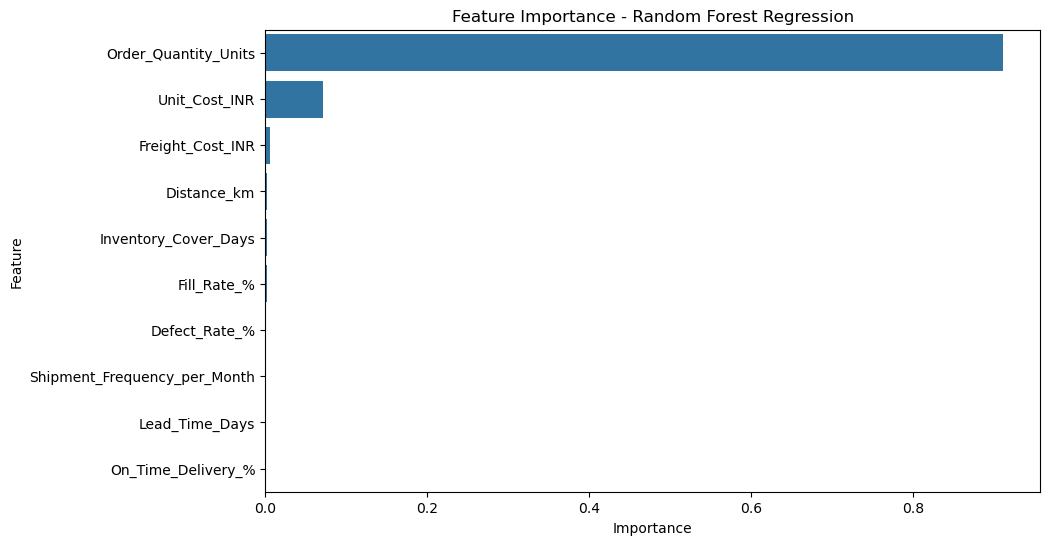

In [47]:
plt.figure(figsize=(10,6))
sns.barplot(data=feature_importance, x="Importance", y="Feature")
plt.title("Feature Importance - Random Forest Regression")
plt.show()

## Actual vs Predicted Cost

In [48]:
prediction_comparison = pd.DataFrame({"Actual Cost": y_test.values,"Predicted Cost": y_pred_rf})
prediction_comparison.head(10)

,Actual Cost,Predicted Cost
0,62875.30,50636.30560
1,47214.01,41526.75400
2,351529.18,344052.62785
3,321936.57,321841.91380
4,395486.73,371661.67675
5,425935.20,389417.06880
6,516275.67,531001.61745
7,68929.52,73273.70750
8,102590.71,96286.38365
9,382418.54,372069.59020


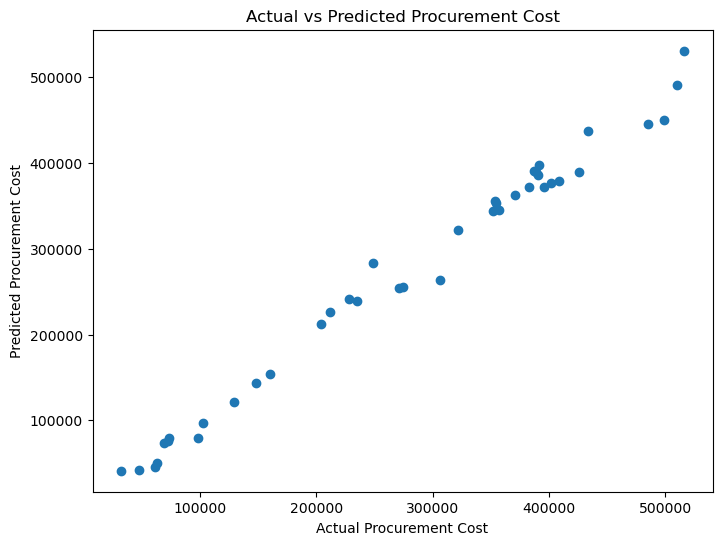

In [30]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_rf)
plt.xlabel("Actual Procurement Cost")
plt.ylabel("Predicted Procurement Cost")
plt.title("Actual vs Predicted Procurement Cost")
plt.show()

## PART B — Classification

In [32]:
X_class = df[a] ## Classify Dataset
y_class = df["Performance_Class"]

In [33]:
print(y_class.value_counts())

Performance_Class
High    100
Low     100
Name: count, dtype: int64


In [34]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42, ## Normally we use 42
    stratify=y_class
)

In [49]:
logistic_model = LogisticRegression(max_iter=5000)
logistic_model.fit(X_train_c, y_train_c)
y_pred_logistic = logistic_model.predict(X_test_c)

In [50]:
accuracy_logistic = accuracy_score(y_test_c,y_pred_logistic)
print("Logistic Regression Accuracy:",accuracy_logistic)

Logistic Regression Accuracy: 0.95


In [51]:
print(
    classification_report(
        y_test_c,
        y_pred_logistic 
    ))

              precision    recall  f1-score   support

        High       1.00      0.90      0.95        20
         Low       0.91      1.00      0.95        20

    accuracy                           0.95        40
   macro avg       0.95      0.95      0.95        40
weighted avg       0.95      0.95      0.95        40



In [52]:
cm = confusion_matrix(y_test_c,y_pred_logistic)
print(cm)

[[18  2]
 [ 0 20]]


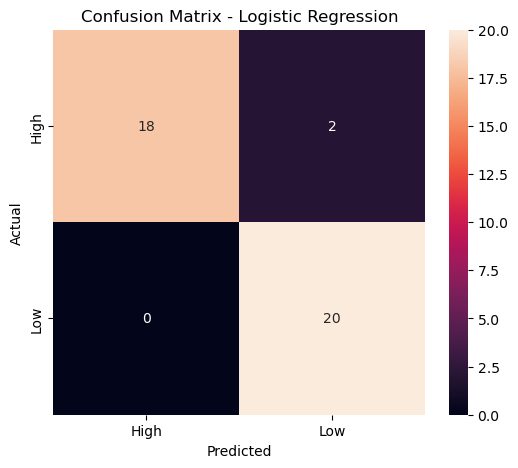

In [53]:
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",xticklabels=["High", "Low"],yticklabels=["High", "Low"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [54]:
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train_c,y_train_c)
y_pred_tree = decision_tree.predict(X_test_c)
accuracy_tree = accuracy_score(y_test_c,y_pred_tree)
print("Decision Tree Accuracy:", accuracy_tree)

Decision Tree Accuracy: 0.8


In [55]:
## Random Forest Classification

rf_classifier = RandomForestClassifier(n_estimators=200,random_state=42)
rf_classifier.fit(X_train_c,y_train_c)
y_pred_rf_class = rf_classifier.predict(X_test_c)
accuracy_rf_class = accuracy_score(y_test_c,y_pred_rf_class)
print("Random Forest Classification Accuracy:",accuracy_rf_class)

Random Forest Classification Accuracy: 0.95


In [56]:
classification_results = pd.DataFrame({"Model": ["Logistic Regression","Decision Tree","Random Forest"],
                                       "Accuracy": [accuracy_logistic,accuracy_tree,accuracy_rf_class]})
classification_results

,Model,Accuracy
0,Logistic Regression,0.95
1,Decision Tree,0.80
2,Random Forest,0.95


In [57]:
cm_rf = confusion_matrix(y_test_c,y_pred_rf_class)
print(cm_rf)

[[19  1]
 [ 1 19]]


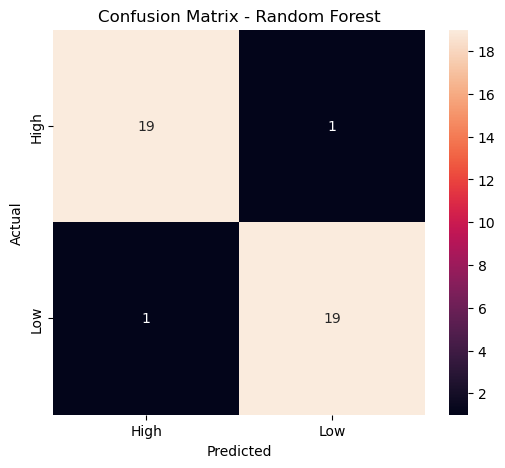

In [58]:
plt.figure(figsize=(6,5))
sns.heatmap(cm_rf,annot=True,fmt="d",xticklabels=["High", "Low"],yticklabels=["High", "Low"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()

## PART C — Supplier Comparison

In [59]:
## Compare Suppliers

supplier_comparison = df.groupby("Supplier")[[
        "Unit_Cost_INR",
        "Lead_Time_Days",
        "On_Time_Delivery_%",
        "Defect_Rate_%",
        "Freight_Cost_INR",
        "Fill_Rate_%",
        "Inventory_Cover_Days",
        "Distance_km",
        "Shipment_Frequency_per_Month",
        "Total_Procurement_Cost_INR"]].mean()
supplier_comparison

,Unit_Cost_INR,Lead_Time_Days,On_Time_Delivery_%,Defect_Rate_%,Freight_Cost_INR,Fill_Rate_%,Inventory_Cover_Days,Distance_km,Shipment_Frequency_per_Month,Total_Procurement_Cost_INR
Supplier,,,,,,,,,,
Supplier A,518.4842,6.594,94.303,2.0082,7246.1831,95.838,20.989,951.73,11.65,286965.4330
Supplier B,495.3180,8.348,87.302,4.0850,7532.9629,89.361,22.846,1000.36,11.87,264493.3596


## PART D — Suggested Models

['Dataset', 'Data Dictionary', 'Exercises']
['Dataset', 'Data Dictionary', 'Exercises']
Shape: (200, 13)

Columns:
Index(['Supplier', 'Order_Quantity_Units', 'Unit_Cost_INR', 'Lead_Time_Days',
       'On_Time_Delivery_%', 'Defect_Rate_%', 'Freight_Cost_INR',
       'Fill_Rate_%', 'Inventory_Cover_Days', 'Distance_km',
       'Shipment_Frequency_per_Month', 'Total_Procurement_Cost_INR',
       'Performance_Class'],
      dtype='object')

Missing Values:
Supplier                        0
Order_Quantity_Units            0
Unit_Cost_INR                   0
Lead_Time_Days                  0
On_Time_Delivery_%              0
Defect_Rate_%                   0
Freight_Cost_INR                0
Fill_Rate_%                     0
Inventory_Cover_Days            0
Distance_km                     0
Shipment_Frequency_per_Month    0
Total_Procurement_Cost_INR      0
Performance_Class               0
dtype: int64

Supplier Distribution:
Supplier
Supplier A    100
Supplier B    100
Name: count, dtype:

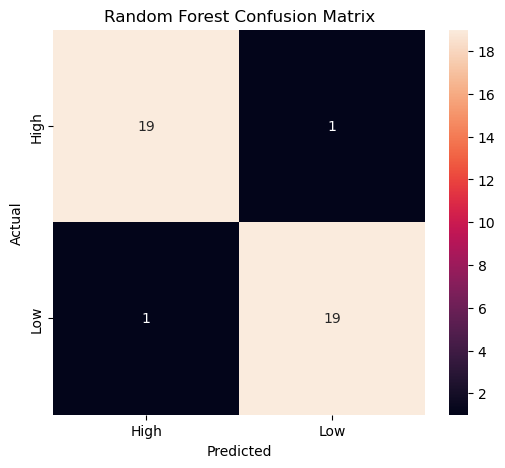


Supplier Comparison
            Unit_Cost_INR  Lead_Time_Days  On_Time_Delivery_%  Defect_Rate_%  \
Supplier                                                                       
Supplier A         518.48            6.59                94.3           2.01   
Supplier B         495.32            8.35                87.3           4.08   

            Freight_Cost_INR  Fill_Rate_%  Inventory_Cover_Days  Distance_km  \
Supplier                                                                       
Supplier A           7246.18        95.84                 20.99       951.73   
Supplier B           7532.96        89.36                 22.85      1000.36   

            Shipment_Frequency_per_Month  Total_Procurement_Cost_INR  
Supplier                                                              
Supplier A                         11.65                   286965.43  
Supplier B                         11.87                   264493.36  


In [65]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# 2. Load Data
excel_file=pd.ExcelFile(r"C:\Users\91945\Desktop\Analytics-3rd Sem Assignment\Python\For Prediction and Classification.xlsx")
print(excel_file.sheet_names)
df=pd.read_excel(r"C:\Users\91945\Desktop\Analytics-3rd Sem Assignment\Python\For Prediction and Classification.xlsx", sheet_name="Dataset")
print(excel_file.sheet_names)

# 3. Information
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nSupplier Distribution:")
print(df["Supplier"].value_counts())
print("\nPerformance Distribution:")
print(df["Performance_Class"].value_counts())

# 4. Features
features = [
    "Order_Quantity_Units",
    "Unit_Cost_INR",
    "Lead_Time_Days",
    "On_Time_Delivery_%",
    "Defect_Rate_%",
    "Freight_Cost_INR",
    "Fill_Rate_%",
    "Inventory_Cover_Days",
    "Distance_km",
    "Shipment_Frequency_per_Month"
]

# 5. Regression
X = df[features]
y = df["Total_Procurement_Cost_INR"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train,y_train)
linear_prediction = linear_model.predict(X_test)
linear_mae = mean_absolute_error(y_test,linear_prediction)
linear_rmse = np.sqrt(mean_squared_error(y_test,linear_prediction))
linear_r2 = r2_score(y_test,linear_prediction)

# Random Forest Regression
rf_regressor = RandomForestRegressor(n_estimators=200,random_state=42)
rf_regressor.fit(X_train,y_train)
rf_prediction = rf_regressor.predict(X_test)
rf_mae = mean_absolute_error(y_test,rf_prediction)
rf_rmse = np.sqrt(mean_squared_error(y_test,rf_prediction))
rf_r2 = r2_score(y_test,rf_prediction)

# Regression Results
regression_results = pd.DataFrame({
    "Model": ["Linear Regression","Random Forest"],
    "MAE": [linear_mae,rf_mae],
    "RMSE": [linear_rmse,rf_rmse],
    "R2": [linear_r2,rf_r2]
})
print("\nRegression Results")
print(regression_results)

# 6. Classification
X_class = df[features]
y_class = df["Performance_Class"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

# Logistic Regression
logistic_model = LogisticRegression(max_iter=5000)
logistic_model.fit(X_train_c,y_train_c)
logistic_prediction = logistic_model.predict(X_test_c)
logistic_accuracy = accuracy_score(y_test_c,logistic_prediction)

# Decision Tree
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train_c,y_train_c)
tree_prediction = decision_tree.predict(X_test_c)
tree_accuracy = accuracy_score(y_test_c,tree_prediction)

# Random Forest Classification
rf_classifier = RandomForestClassifier(n_estimators=200,random_state=42)
rf_classifier.fit(X_train_c,y_train_c)
rf_class_prediction = rf_classifier.predict(X_test_c)
rf_class_accuracy = accuracy_score(y_test_c,rf_class_prediction)

# Classification Results
classification_results = pd.DataFrame({
    "Model": ["Logistic Regression","Decision Tree","Random Forest"],
    "Accuracy": [logistic_accuracy,tree_accuracy,rf_class_accuracy]
})
print("\nClassification Results")
print(classification_results)

# 7. Matrix
cm = confusion_matrix(y_test_c,rf_class_prediction)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",xticklabels=["High", "Low"],yticklabels=["High", "Low"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

# 8. Supplier Comparison
supplier_comparison = df.groupby("Supplier")[
    [
        "Unit_Cost_INR",
        "Lead_Time_Days",
        "On_Time_Delivery_%",
        "Defect_Rate_%",
        "Freight_Cost_INR",
        "Fill_Rate_%",
        "Inventory_Cover_Days",
        "Distance_km",
        "Shipment_Frequency_per_Month",
        "Total_Procurement_Cost_INR"
    ]].mean()
print("\nSupplier Comparison")
print(supplier_comparison.round(2))